# **Loading Libraries and Data**



In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor
import matplotlib.pylab as plt
from sklearn.metrics import mean_squared_error
import seaborn as sns
from pandas.plotting import scatter_matrix, parallel_coordinates

!pip install dmba
from dmba import classificationSummary, regressionSummary
from dmba import gainsChart, liftChart
%matplotlib inline

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 16.0 MB/s eta 0:00:00
Colab environment detected.


In [ ]:
# Loading Data
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
file_name = 'SBAnational.csv'
SBA_df = pd.read_csv('/content/drive/My Drive/MSBA/MSBA BA Project/' + file_name)
SBA_df

<ipython-input-4-a84700c54df5>:2: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  SBA_df = pd.read_csv('/content/drive/My Drive/MSBA/MSBA BA Project/' + file_name)


,LoanNr_ChkDgt,Name,City,State,Zip,Bank,BankState,NAICS,ApprovalDate,ApprovalFY,...,RevLineCr,LowDoc,ChgOffDate,DisbursementDate,DisbursementGross,BalanceGross,MIS_Status,ChgOffPrinGr,GrAppv,SBA_Appv
0,1000014003,ABC HOBBYCRAFT,EVANSVILLE,IN,47711,FIFTH THIRD BANK,OH,451120,28-Feb-97,1997,...,N,Y,NaN,28-Feb-99,"$60,000.00",$0.00,P I F,$0.00,"$60,000.00","$48,000.00"
1,1000024006,LANDMARK BAR & GRILLE (THE),NEW PARIS,IN,46526,1ST SOURCE BANK,IN,722410,28-Feb-97,1997,...,N,Y,NaN,31-May-97,"$40,000.00",$0.00,P I F,$0.00,"$40,000.00","$32,000.00"
2,1000034009,"WHITLOCK DDS, TODD M.",BLOOMINGTON,IN,47401,GRANT COUNTY STATE BANK,IN,621210,28-Feb-97,1997,...,N,N,NaN,31-Dec-97,"$287,000.00",$0.00,P I F,$0.00,"$287,000.00","$215,250.00"
3,1000044001,"BIG BUCKS PAWN & JEWELRY, LLC",BROKEN ARROW,OK,74012,1ST NATL BK & TR CO OF BROKEN,OK,0,28-Feb-97,1997,...,N,Y,NaN,30-Jun-97,"$35,000.00",$0.00,P I F,$0.00,"$35,000.00","$28,000.00"
4,1000054004,"ANASTASIA CONFECTIONS, INC.",ORLANDO,FL,32801,FLORIDA BUS. DEVEL CORP,FL,0,28-Feb-97,1997,...,N,N,NaN,14-May-97,"$229,000.00",$0.00,P I F,$0.00,"$229,000.00","$229,000.00"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
899159,9995573004,FABRIC FARMS,UPPER ARLINGTON,OH,43221,JPMORGAN CHASE BANK NATL ASSOC,IL,451120,27-Feb-97,1997,...,0,N,NaN,30-Sep-97,"$70,000.00",$0.00,P I F,$0.00,"$70,000.00","$56,000.00"
899160,9995603000,FABRIC FARMS,COLUMBUS,OH,43221,JPMORGAN CHASE BANK NATL ASSOC,IL,451130,27-Feb-97,1997,...,Y,N,NaN,31-Oct-97,"$85,000.00",$0.00,P I F,$0.00,"$85,000.00","$42,500.00"
899161,9995613003,"RADCO MANUFACTURING CO.,INC.",SANTA MARIA,CA,93455,"RABOBANK, NATIONAL ASSOCIATION",CA,332321,27-Feb-97,1997,...,N,N,NaN,30-Sep-97,"$300,000.00",$0.00,P I F,$0.00,"$300,000.00","$225,000.00"
899162,9995973006,"MARUTAMA HAWAII, INC.",HONOLULU,HI,96830,BANK OF HAWAII,HI,0,27-Feb-97,1997,...,N,Y,8-Mar-00,31-Mar-97,"$75,000.00",$0.00,CHGOFF,"$46,383.00","$75,000.00","$60,000.00"


# **Examining Dataset**

In [ ]:
SBA_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 899164 entries, 0 to 899163
Data columns (total 27 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   LoanNr_ChkDgt      899164 non-null  int64  
 1   Name               899150 non-null  object 
 2   City               899134 non-null  object 
 3   State              899150 non-null  object 
 4   Zip                899164 non-null  int64  
 5   Bank               897605 non-null  object 
 6   BankState          897598 non-null  object 
 7   NAICS              899164 non-null  int64  
 8   ApprovalDate       899164 non-null  object 
 9   ApprovalFY         899164 non-null  object 
 10  Term               899164 non-null  int64  
 11  NoEmp              899164 non-null  int64  
 12  NewExist           899028 non-null  float64
 13  CreateJob          899164 non-null  int64  
 14  RetainedJob        899164 non-null  int64  
 15  FranchiseCode      899164 non-null  int64  
 16  Ur

In [ ]:
for column in SBA_df.columns:
    print(f"Value counts for {column}:")
    print(SBA_df[column].value_counts())
    print("\n")  # Add a newline for readability between columns

Value counts for LoanNr_ChkDgt:
LoanNr_ChkDgt
1000014003    1
5944984007    1
5944874009    1
5944884001    1
5944904005    1
             ..
3072874001    1
3072875008    1
3072885000    1
3072886007    1
9996003010    1
Name: count, Length: 899164, dtype: int64


Value counts for Name:
Name
SUBWAY                            1269
QUIZNO'S SUBS                      433
COLD STONE CREAMERY                366
QUIZNO'S                           345
DOMINO'S PIZZA                     329
                                  ... 
Mohammad N. Hassan (epc) for C       1
N.J. Yellow Tale Flower              1
CEF INC.                             1
SCANNELL AND ASSOCIATES LP           1
PACIFIC TRADEWINDS FAN & LIGHT       1
Name: count, Length: 779583, dtype: int64


Value counts for City:
City
LOS ANGELES                       11558
HOUSTON                           10247
NEW YORK                           7846
CHICAGO                            6036
MIAMI                              5594
     

Value counts for MIS_Status:

MIS_Status

*   P I F     739609
*   CHGOFF    157558


In [ ]:
# Proportion of MIS_Status
SBA_df['MIS_Status'].value_counts(normalize=True)

,proportion
MIS_Status,
P I F,0.824383
CHGOFF,0.175617


In [ ]:
# Descriptive Stats
SBA_df.describe()

,LoanNr_ChkDgt,Zip,NAICS,Term,NoEmp,NewExist,CreateJob,RetainedJob,FranchiseCode,UrbanRural
count,8.991640e+05,899164.000000,899164.000000,899164.000000,899164.000000,899028.000000,899164.000000,899164.000000,899164.000000,899164.000000
mean,4.772612e+09,53804.391241,398660.950146,110.773078,11.411353,1.280404,8.430376,10.797257,2753.725933,0.757748
std,2.538175e+09,31184.159152,263318.312759,78.857305,74.108196,0.451750,236.688165,237.120600,12758.019136,0.646436
min,1.000014e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.589758e+09,27587.000000,235210.000000,60.000000,2.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,4.361439e+09,55410.000000,445310.000000,84.000000,4.000000,1.000000,0.000000,1.000000,1.000000,1.000000
75%,6.904627e+09,83704.000000,561730.000000,120.000000,10.000000,2.000000,1.000000,4.000000,1.000000,1.000000
max,9.996003e+09,99999.000000,928120.000000,569.000000,9999.000000,2.000000,8800.000000,9500.000000,99999.000000,2.000000


In [ ]:
# See NA values
SBA_df.isna().sum()

,0
LoanNr_ChkDgt,0
Name,14
City,30
State,14
Zip,0
Bank,1559
BankState,1566
NAICS,0
ApprovalDate,0
ApprovalFY,0


# **Dropping Variables**

Bank indentifier-related variables were dropped as they do not provide relevance to the analysis.

Job related metrics and data with values that would be unknown at time of loan application were removed to ensure an accurate model for new applicants.

In [ ]:
# Drop identifying variable
SBA_df2 = SBA_df.drop(['LoanNr_ChkDgt', 'BankState', 'Name', 'City', 'Zip', 'Bank', 'ApprovalDate', 'CreateJob', 'RetainedJob', 'ChgOffDate', 'BalanceGross', 'ChgOffPrinGr'], axis=1)
SBA_df2

,State,NAICS,ApprovalFY,Term,NoEmp,NewExist,FranchiseCode,UrbanRural,RevLineCr,LowDoc,DisbursementDate,DisbursementGross,MIS_Status,GrAppv,SBA_Appv
0,IN,451120,1997,84,4,2.00,1,0,N,Y,28-Feb-99,"$60,000.00",P I F,"$60,000.00","$48,000.00"
1,IN,722410,1997,60,2,2.00,1,0,N,Y,31-May-97,"$40,000.00",P I F,"$40,000.00","$32,000.00"
2,IN,621210,1997,180,7,1.00,1,0,N,N,31-Dec-97,"$287,000.00",P I F,"$287,000.00","$215,250.00"
3,OK,0,1997,60,2,1.00,1,0,N,Y,30-Jun-97,"$35,000.00",P I F,"$35,000.00","$28,000.00"
4,FL,0,1997,240,14,1.00,1,0,N,N,14-May-97,"$229,000.00",P I F,"$229,000.00","$229,000.00"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
899159,OH,451120,1997,60,6,1.00,1,0,0,N,30-Sep-97,"$70,000.00",P I F,"$70,000.00","$56,000.00"
899160,OH,451130,1997,60,6,1.00,1,0,Y,N,31-Oct-97,"$85,000.00",P I F,"$85,000.00","$42,500.00"
899161,CA,332321,1997,108,26,1.00,1,0,N,N,30-Sep-97,"$300,000.00",P I F,"$300,000.00","$225,000.00"
899162,HI,0,1997,60,6,1.00,1,0,N,Y,31-Mar-97,"$75,000.00",CHGOFF,"$75,000.00","$60,000.00"


In [ ]:
SBA_df2.dtypes

,0
State,object
NAICS,int64
ApprovalFY,object
Term,int64
NoEmp,int64
NewExist,float64
FranchiseCode,int64
UrbanRural,int64
RevLineCr,object
LowDoc,object


In [ ]:
# Value counts for variables
for column in SBA_df2.columns:
    print(f"Value counts for {column}:")
    print(SBA_df2[column].value_counts())
    print("\n")  # Add a newline for readability between columns

Value counts for State:
State
CA    130619
TX     70458
NY     57693
FL     41212
PA     35170
OH     32622
IL     29669
MA     25272
MN     24373
NJ     24035
WA     23263
GA     22277
WI     21040
MO     20678
CO     20605
MI     20545
UT     18776
AZ     17631
NC     14294
IN     14132
MD     13269
VA     13264
CT     12229
NH     12109
IA     11996
KS     11464
OR     11051
OK      9950
LA      9576
ID      9498
TN      9403
RI      9028
MT      8749
AL      8362
NV      8024
KY      7723
MS      7686
NE      6386
AR      6341
NM      6033
ME      5944
SC      5597
VT      5454
ND      5245
SD      4431
HI      3610
WV      3287
WY      2839
AK      2405
DE      2220
DC      1613
Name: count, dtype: int64


Value counts for NAICS:
NAICS
0         201948
722110     27989
722211     19448
811111     14585
621210     14048
           ...  
927110         1
327410         1
314992         1
922110         1
325192         1
Name: count, Length: 1312, dtype: int64


Value counts for App

# **Permanent Transformations**

In [ ]:
# Value counts for LowDoc and RevLineCr
print(SBA_df2['LowDoc'].value_counts())
print(SBA_df2['RevLineCr'].value_counts())
print(SBA_df2['FranchiseCode'].value_counts())

LowDoc
N    782822
Y    110335
0      1491
C       758
S       603
A       497
R        75
1         1
Name: count, dtype: int64
RevLineCr
N    420288
0    257602
Y    201397
T     15284
1        23
R        14
`        11
2         6
C         2
3         1
,         1
7         1
A         1
5         1
.         1
4         1
-         1
Q         1
Name: count, dtype: int64
FranchiseCode
1        638554
0        208835
78760      3373
68020      1921
50564      1034
          ...  
24421         1
61615         1
81580         1
83876         1
15930         1
Name: count, Length: 2768, dtype: int64


## Turn MIS_Status (outcome variable) to 0 and 1 values for easier analysis. 0 represents a loan paid off in full and 1 represents a loan default.

*   1 = High Risk
*   0 = Low Risk

In [ ]:
# Change MIS_Status to 0 and 1
SBA_df2['MIS_Status'] = [1 if status == 'CHGOFF' else 0
                          for status in SBA_df['MIS_Status']]

# Value counts for MIS_Status
print(SBA_df2['MIS_Status'].value_counts())

MIS_Status
0    741606
1    157558
Name: count, dtype: int64


Modify column data to appropriate data values and column types.

In [ ]:
# Turning FranchiseCode into Categorical
# Combine 0 and 1 as 0 in FranchiseCode
SBA_df2['FranchiseCode'] = SBA_df2['FranchiseCode'].replace({1: 0})

# Replace every other FranchiseCode value as 1
SBA_df2['FranchiseCode'] = np.where(SBA_df2['FranchiseCode'] == 0, 0, 1)
print(SBA_df2['FranchiseCode'].value_counts())

FranchiseCode
0    847389
1     51775
Name: count, dtype: int64


In [ ]:
# Extract the year from DisbursementDate directly
SBA_df2['DisbursementYear'] = pd.to_datetime(SBA_df2['DisbursementDate'], format="%d-%b-%y", errors='coerce').dt.year

# Drop DisbursementDate
SBA_df2 = SBA_df2.drop(['DisbursementDate'], axis=1)

# Check the value counts for the year
print(SBA_df2['DisbursementYear'].value_counts().sort_index(ascending=False))

DisbursementYear
2068.00        2
2066.00        1
2048.00        1
2028.00        1
2020.00        1
2014.00      234
2013.00     2366
2012.00     5766
2011.00    11399
2010.00    16757
2009.00    21756
2008.00    37290
2007.00    68945
2006.00    79309
2005.00    74771
2004.00    70208
2003.00    59058
2002.00    45519
2001.00    37309
2000.00    39757
1999.00    39804
1998.00    35275
1997.00    40737
1996.00    37648
1995.00    44241
1994.00    30775
1993.00    22281
1992.00    19589
1991.00    15702
1990.00    14461
1989.00    11786
1988.00     2066
1987.00     2176
1986.00     2054
1985.00     2006
1984.00     1953
1983.00     1205
1982.00      653
1981.00      454
1980.00      505
1979.00      336
1978.00      249
1977.00      130
1976.00       67
1975.00       46
1974.00       35
1973.00       45
1972.00       35
1971.00       15
1970.00       14
1969.00        3
Name: count, dtype: int64


In [ ]:
# Look at MIS = 1, and DisbursementYear, and order by DisbursementYear
SBA_df2[SBA_df2['MIS_Status'] == 1].groupby('DisbursementYear').size().sort_index()

,0
DisbursementYear,
1969.00,2
1970.00,13
1971.00,14
1972.00,29
1973.00,43
1974.00,31
1975.00,45
1976.00,64
1977.00,119


Competition establishes time frame from 1987-2014. Dropped values outside of this data range.

In [ ]:
# Drop rows where DisbursementYear is less than 1987 or greater than 2014
SBA_df2 = SBA_df2[~((SBA_df2['DisbursementYear'] < 1987) | (SBA_df2['DisbursementYear'] > 2014))]

# Value counts for DisbursementYear
SBA_df2['DisbursementYear'] = SBA_df2['DisbursementYear'].astype('category')
print(SBA_df2['DisbursementYear'].value_counts())

DisbursementYear
2006.00    79309
2005.00    74771
2004.00    70208
2007.00    68945
2003.00    59058
2002.00    45519
1995.00    44241
1997.00    40737
1999.00    39804
2000.00    39757
1996.00    37648
2001.00    37309
2008.00    37290
1998.00    35275
1994.00    30775
1993.00    22281
2009.00    21756
1992.00    19589
2010.00    16757
1991.00    15702
1990.00    14461
1989.00    11786
2011.00    11399
2012.00     5766
2013.00     2366
1987.00     2176
1988.00     2066
2014.00      234
Name: count, dtype: int64


<ipython-input-157-150442ad0f19>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  SBA_df2['DisbursementYear'] = SBA_df2['DisbursementYear'].astype('category')


Map industry values to appropriate groups based on NAICS to allow for better analysis. Assuming industry groups will have similar results.

In [ ]:
# Define the mapping for industry groups based on the first two digits of NAICS
industry_mapping = {
    '11': 'Resource_and_Industrial_Production',
    '21': 'Resource_and_Industrial_Production',
    '22': 'Resource_and_Industrial_Production',
    '23': 'Resource_and_Industrial_Production',
    '31': 'Resource_and_Industrial_Production',
    '32': 'Resource_and_Industrial_Production',
    '33': 'Resource_and_Industrial_Production',
    '42': 'Trade_and_Logistics',
    '44': 'Trade_and_Logistics',
    '45': 'Trade_and_Logistics',
    '48': 'Trade_and_Logistics',
    '49': 'Trade_and_Logistics',
    '52': 'Financial_and_Professional_Services',
    '53': 'Financial_and_Professional_Services',
    '54': 'Financial_and_Professional_Services',
    '55': 'Financial_and_Professional_Services',
    '56': 'Financial_and_Professional_Services',
    '61': 'Public_and_Social_Services',
    '62': 'Public_and_Social_Services',
    '92': 'Public_and_Social_Services',
    '51': 'Information_Arts_and_Hospitality',
    '71': 'Information_Arts_and_Hospitality',
    '72': 'Information_Arts_and_Hospitality',
    '81': 'Information_Arts_and_Hospitality'
}

# Extract the first two digits of NAICS and map to industry groups
SBA_df2['Industry'] = SBA_df2['NAICS'].astype(str).str[:2].map(industry_mapping)

# Drop NAICS column if needed
SBA_df2 = SBA_df2.drop(['NAICS'], axis=1)

# Display value counts for each industry group
print(SBA_df2['Industry'].value_counts())

Industry
Trade_and_Logistics                    198524
Information_Arts_and_Hospitality       166235
Resource_and_Industrial_Production     146193
Financial_and_Professional_Services    124240
Public_and_Social_Services              62020
Name: count, dtype: int64


In [ ]:
# Clean RevLineCr turn 0 to N, 1 to Y, T to Y
SBA_df2['RevLineCr'] = SBA_df2['RevLineCr'].replace({0: 'N', 1: 'Y', 'T': 'Y'})
SBA_df2['RevLineCr'] = SBA_df2['RevLineCr'].replace({'N': 0, 'Y': 1})

# Clean LowDoc turn N and Y to 0 and 1
SBA_df2['LowDoc'] = SBA_df2['LowDoc'].replace({'N': 0, 'Y': 1})

# Drop data entry errors on LowDoc, RevLineCr Keep only 1 and 0
SBA_df2 = SBA_df2[SBA_df2['LowDoc'].isin([1, 0])]
SBA_df2 = SBA_df2[SBA_df2['RevLineCr'].isin([1, 0])]

# Clean NewExist drop 0
SBA_df2['NewExist'] = SBA_df2['NewExist'].replace({0: np.nan})

In [ ]:
# Value counts for LowDoc, RevLineCr, FranchiseCode, and Industry, verifying transformations
print(SBA_df2['LowDoc'].value_counts())
print(SBA_df2['RevLineCr'].value_counts())
print(SBA_df2['FranchiseCode'].value_counts())
print(SBA_df2['Industry'].value_counts())
print(SBA_df2['NewExist'].value_counts())

LowDoc
0    564547
1     57442
Name: count, dtype: int64
RevLineCr
0    406325
1    215664
Name: count, dtype: int64
FranchiseCode
0    596260
1     25729
Name: count, dtype: int64
Industry
Trade_and_Logistics                    136859
Resource_and_Industrial_Production     108300
Information_Arts_and_Hospitality        99260
Financial_and_Professional_Services     91757
Public_and_Social_Services              40043
Name: count, dtype: int64
NewExist
1.00    453793
2.00    167111
Name: count, dtype: int64


Data cleaning of observations by turning values into float types for easier analysis.

In [ ]:
# Cleaning Numerical variables
# Turn numerical variables into int type
SBA_df2['NoEmp'] = SBA_df2['NoEmp'].astype(int)

# Remove $ sign from DisbursementGross, GrAppv, SBA_Appv
SBA_df2['DisbursementGross'] = SBA_df2['DisbursementGross'].str.replace('$', '')
SBA_df2['GrAppv'] = SBA_df2['GrAppv'].str.replace('$', '')
SBA_df2['SBA_Appv'] = SBA_df2['SBA_Appv'].str.replace('$', '')

# Remove commas from DisbursementGross, GrAppv, SBA_Appv
SBA_df2['DisbursementGross'] = SBA_df2['DisbursementGross'].str.replace(',', '')
SBA_df2['GrAppv'] = SBA_df2['GrAppv'].str.replace(',', '')
SBA_df2['SBA_Appv'] = SBA_df2['SBA_Appv'].str.replace(',', '')

# Turn these into float type
SBA_df2['DisbursementGross'] = SBA_df2['DisbursementGross'].astype(float)
SBA_df2['GrAppv'] = SBA_df2['GrAppv'].astype(float)
SBA_df2['SBA_Appv'] = SBA_df2['SBA_Appv'].astype(float)

Review missing values from observations and drop them from data.

In [ ]:
# Count NA
SBA_df2.isna().sum()

,0
State,13
ApprovalFY,0
Term,0
NoEmp,0
NewExist,1085
FranchiseCode,0
UrbanRural,0
RevLineCr,0
LowDoc,0
DisbursementGross,0


In [ ]:
# Drop NA
SBA_df2 = SBA_df2.dropna()

# Verify
SBA_df2.isna().sum()

,0
State,0
ApprovalFY,0
Term,0
NoEmp,0
NewExist,0
FranchiseCode,0
UrbanRural,0
RevLineCr,0
LowDoc,0
DisbursementGross,0


# **Binning Variables**

Review of variable "Term". An average business loan term is 10 year contract, binned by this time frame.

In [ ]:
# Value Counts for Term
SBA_df2['Term'].value_counts()

,count
Term,
84,147978
60,42046
240,32928
120,27133
36,12463
...,...
382,1
385,1
374,1


In [ ]:
# Average Term
SBA_df2['Term'].mean()

92.87652920940428

In [ ]:
# Bin Term by above 10 years and below 10 years
SBA_df2['Term_Category'] = SBA_df2['Term'].apply(lambda x: 'Above 10 years' if x > 120 else 'Below 10 years')

# Drop the original 'Term' column
SBA_df2.drop(columns=['Term'], inplace=True)

# Check the distribution of the new 'Term_Category' variable
print(SBA_df2['Term_Category'].value_counts())

Term_Category
Below 10 years    399361
Above 10 years     74168
Name: count, dtype: int64


Mapping State into regions for easier analysis.

In [ ]:
# Bin State into Regions
# Define state-to-region mapping
state_region_mapping = {
    'Northeast': ['CT', 'ME', 'MA', 'NH', 'RI', 'VT', 'NJ', 'NY', 'PA'],
    'Southeast': ['DE', 'FL', 'GA', 'MD', 'NC', 'SC', 'VA', 'WV', 'AL', 'KY', 'MS', 'TN'],
    'Midwest': ['IL', 'IN', 'MI', 'OH', 'WI', 'IA', 'KS', 'MN', 'MO', 'NE', 'ND', 'SD'],
    'Southwest': ['AZ', 'NM', 'OK', 'TX'],
    'West': ['CO', 'ID', 'MT', 'NV', 'UT', 'WY', 'AK', 'CA', 'HI', 'OR', 'WA']
}

# Invert the mapping to assign each state to its region
region_map = {state: region for region, states in state_region_mapping.items() for state in states}

# Map states to regions
SBA_df2['Region'] = SBA_df2['State'].map(region_map)

# Drop State column
SBA_df2 = SBA_df2.drop(['State'], axis=1)

# Display value counts for each region
print(SBA_df2['Region'].value_counts())

Region
West         121780
Northeast    109261
Midwest      107715
Southeast     79579
Southwest     47100
Name: count, dtype: int64


# **Graphing Categorical Variables**

In [ ]:
SBA_df2.dtypes

,0
ApprovalFY,object
NoEmp,int64
NewExist,float64
FranchiseCode,int64
UrbanRural,int64
RevLineCr,object
LowDoc,object
DisbursementGross,float64
MIS_Status,int64
GrAppv,float64


In [ ]:
# Looking at value counts
for column in SBA_df2.columns:
    print(f"Value counts for {column}:")
    print(SBA_df2[column].value_counts())
    print("\n")  # Add a newline for readability between columns

Value counts for ApprovalFY:
ApprovalFY
2007    59135
2006    58725
2005    40903
2008    30421
2003    30259
2004    21141
2002    19899
2009    16721
1995    16419
2001    16124
2010    15906
2004    14131
2011    11750
1996    11571
1997    10806
1993    10406
2005     9603
1992     9542
1999     8919
2000     8764
1994     8444
1998     8011
1991     7064
1990     6587
1989     5906
2012     5518
1994     5388
2013     2365
1996     1346
1988      812
1987      679
2014      264
Name: count, dtype: int64


Value counts for NoEmp:
NoEmp
1       89712
2       78071
3       49878
4       39465
5       32257
        ...  
464         1
5084        1
2100        1
4100        1
273         1
Name: count, Length: 434, dtype: int64


Value counts for NewExist:
NewExist
1.00    348792
2.00    124737
Name: count, dtype: int64


Value counts for FranchiseCode:
FranchiseCode
0    459027
1     14502
Name: count, dtype: int64


Value counts for UrbanRural:
UrbanRural
1    299084
0    109516
2  

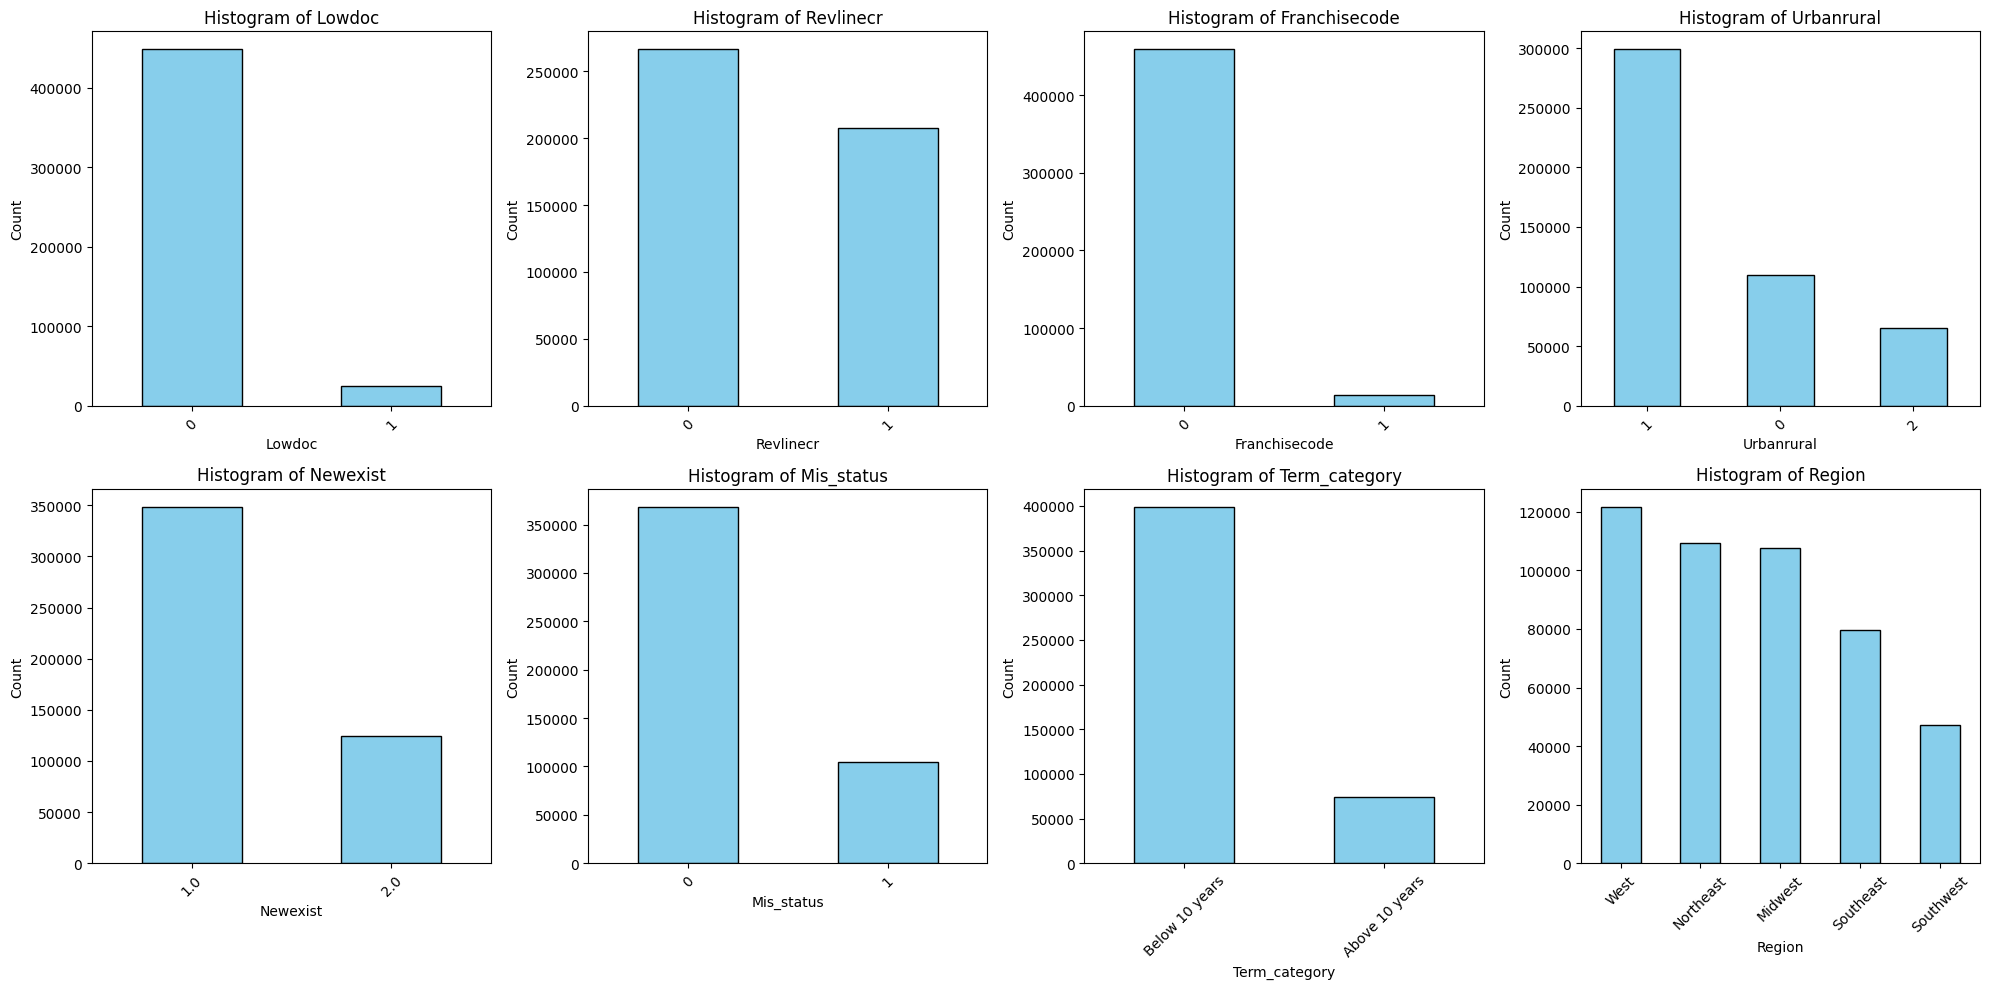

In [ ]:
# Categorical Variables
SBA_df3 = SBA_df2[['LowDoc', 'RevLineCr', 'FranchiseCode', 'UrbanRural', 'NewExist', 'MIS_Status', 'Term_Category', 'Region']]

# Set up subplots with 2 rows and 4 columns
fig, axes = plt.subplots(2, 4, figsize=(20, 10))  # Adjust width and height as needed
axes = axes.flatten()  # Flatten the 2D array of axes to iterate easily

# Loop through each variable and corresponding axis
for ax, var in zip(axes, SBA_df3.columns):
    SBA_df3[var].value_counts().plot(kind='bar', ax=ax, color='skyblue', edgecolor='black')
    ax.set_xlabel(var.capitalize())
    ax.set_ylabel('Count')
    ax.set_title(f'Histogram of {var.capitalize()}')
    ax.tick_params(axis='x', rotation=45)  # Rotate x-axis labels for readability

# Remove any unused subplots
for i in range(len(SBA_df3.columns), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

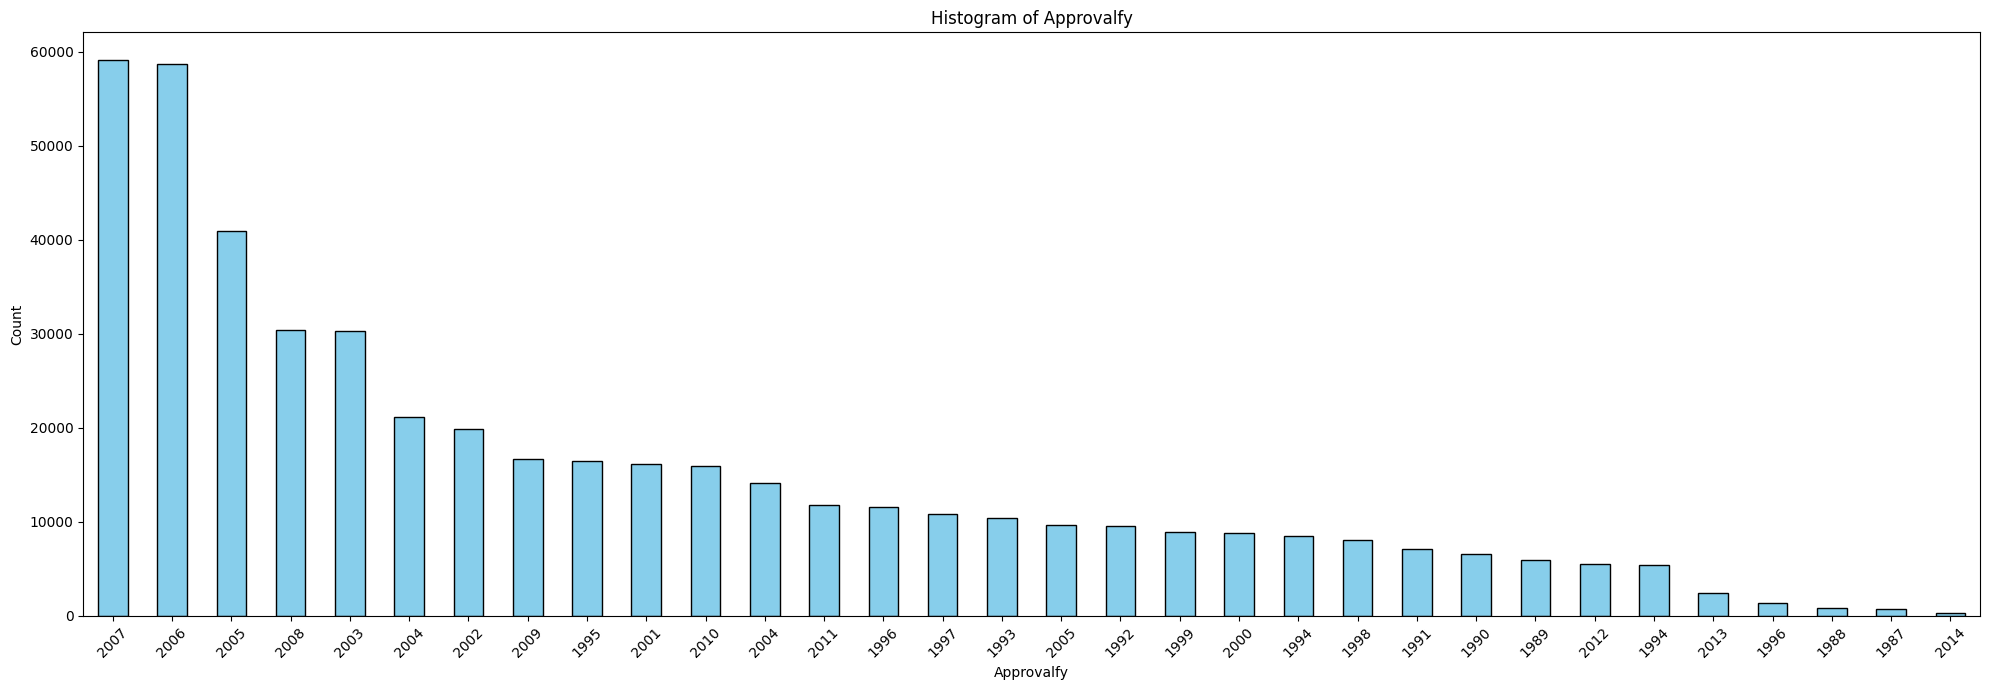

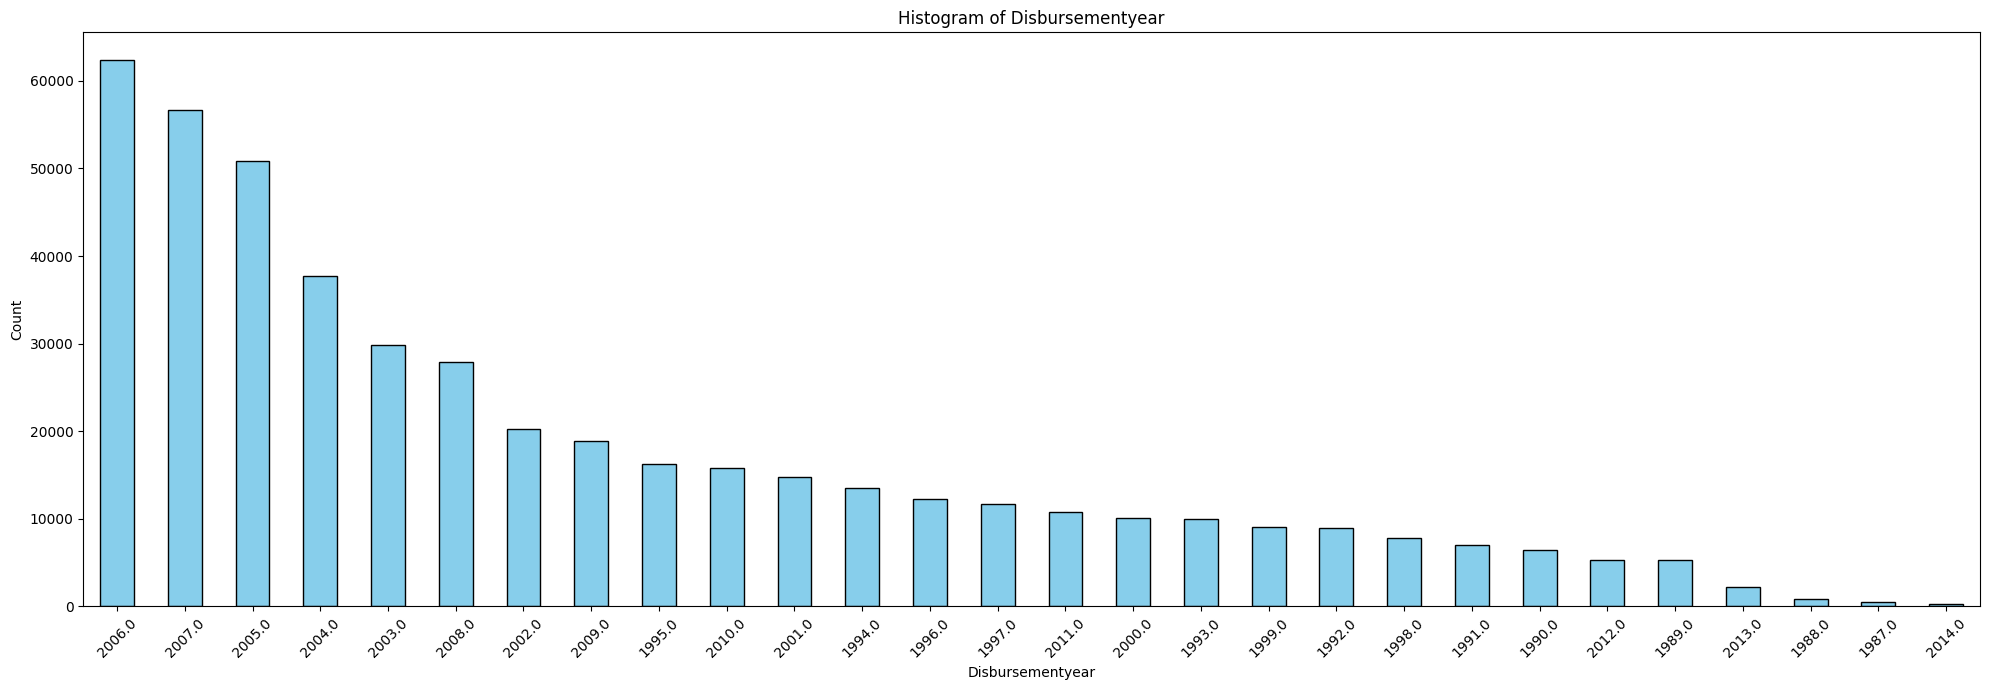

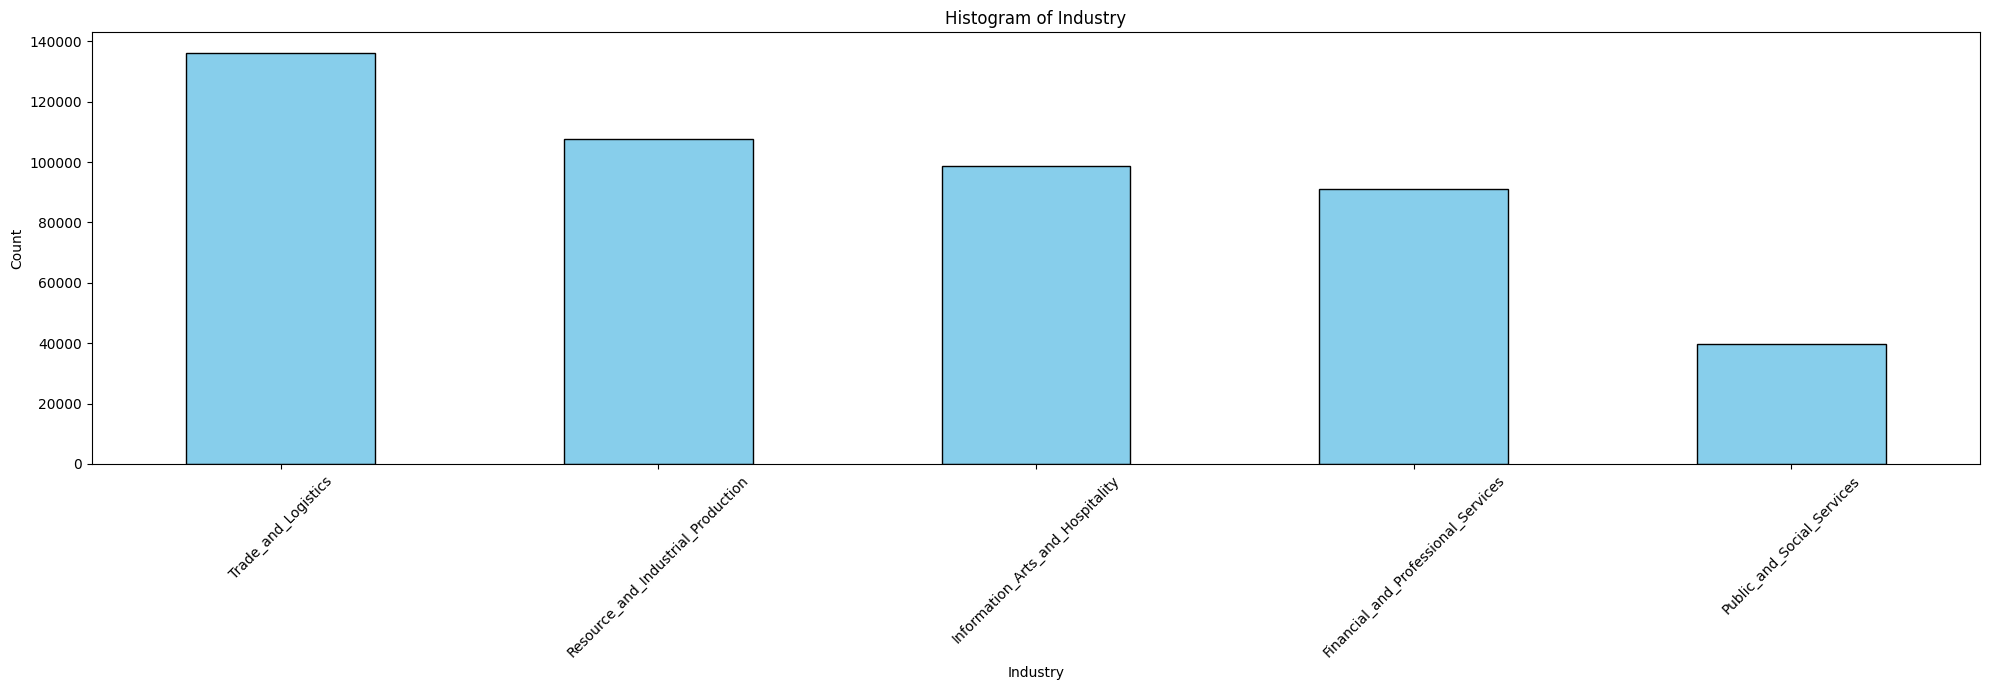

In [ ]:
# Capturing and looking at other categorical variables with many options
SBA_df3 = SBA_df2[['ApprovalFY', 'DisbursementYear', 'Industry']]

# Loop through each variable and plot separately
for var in SBA_df3.columns:
    plt.figure(figsize=(20, 7))  # Set a wider figure size for each plot
    SBA_df3[var].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
    plt.xlabel(var.capitalize())
    plt.ylabel('Count')
    plt.title(f'Histogram of {var.capitalize()}')
    plt.xticks(rotation=45)  # Rotate x-axis labels for readability
    plt.tight_layout()  # Adjust layout for better spacing
    plt.show()


<ipython-input-172-045ee801119a>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  SBA_df3['ApprovalFY'] = pd.to_numeric(SBA_df3['ApprovalFY'], errors='coerce')
<ipython-input-172-045ee801119a>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  SBA_df3.dropna(inplace=True)


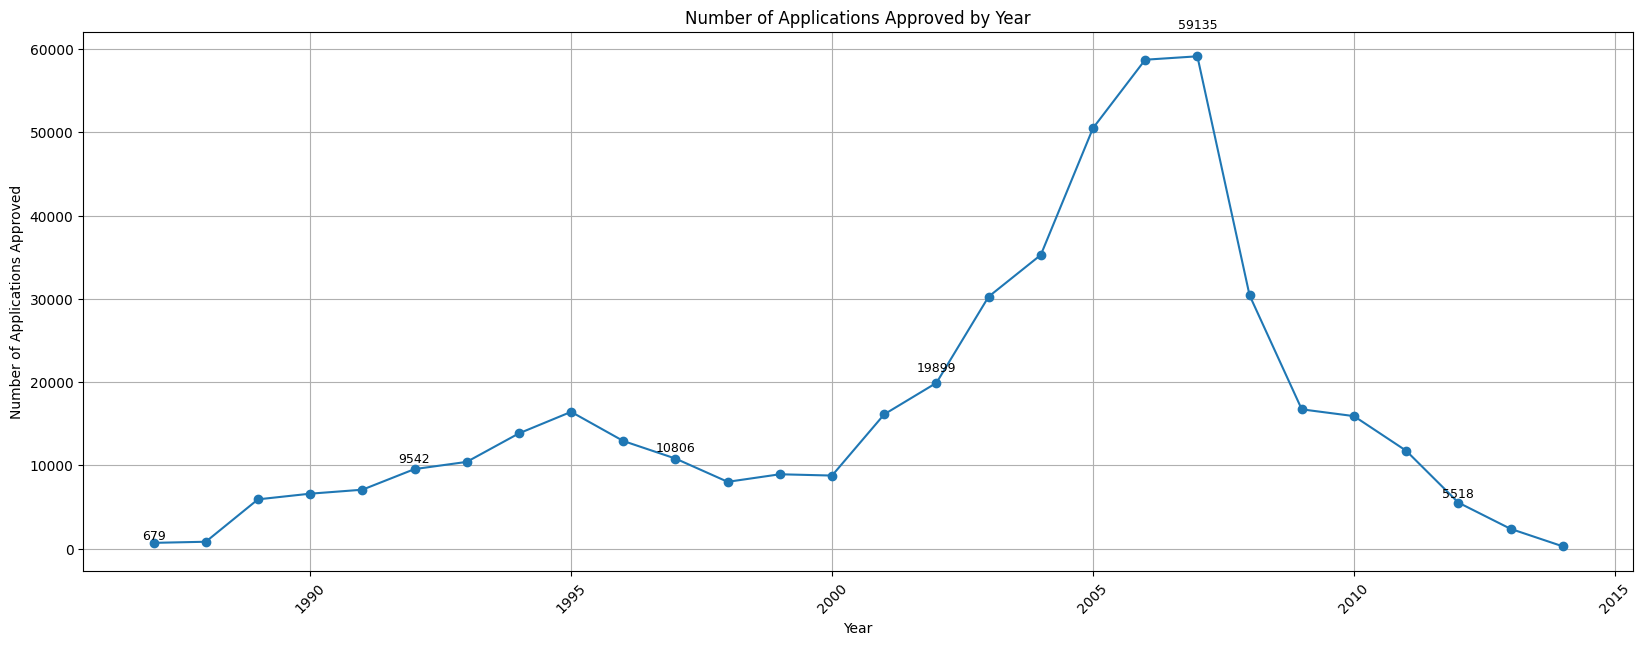

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Time Series Graph for ApprovalFY
SBA_df3 = SBA_df2[['ApprovalFY']]

# Convert ApprovalFY to numeric, forcing errors to NaN and then drop NaNs
SBA_df3['ApprovalFY'] = pd.to_numeric(SBA_df3['ApprovalFY'], errors='coerce')
SBA_df3.dropna(inplace=True)

# Count the number of applications approved each year
approval_count = SBA_df3['ApprovalFY'].value_counts().sort_index()

# Plot
plt.figure(figsize=(20, 7))
plt.plot(approval_count.index, approval_count.values, marker='o')
plt.xlabel('Year')
plt.ylabel('Number of Applications Approved')
plt.title('Number of Applications Approved by Year')
plt.grid(True)
plt.xticks(rotation=45)

# Add selective data labels with an offset above the points
for i, (x, y) in enumerate(zip(approval_count.index, approval_count.values)):
    if i % 5 == 0:  # Show label every 5th year
        plt.text(x, y + y * 0.05, str(y), ha='center', va='bottom', fontsize=9)  # Offset by 5%

plt.show()


<ipython-input-173-1d450c6adf0d>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  SBA_df3['DisbursementYear'] = pd.to_numeric(SBA_df3['DisbursementYear'], errors='coerce')


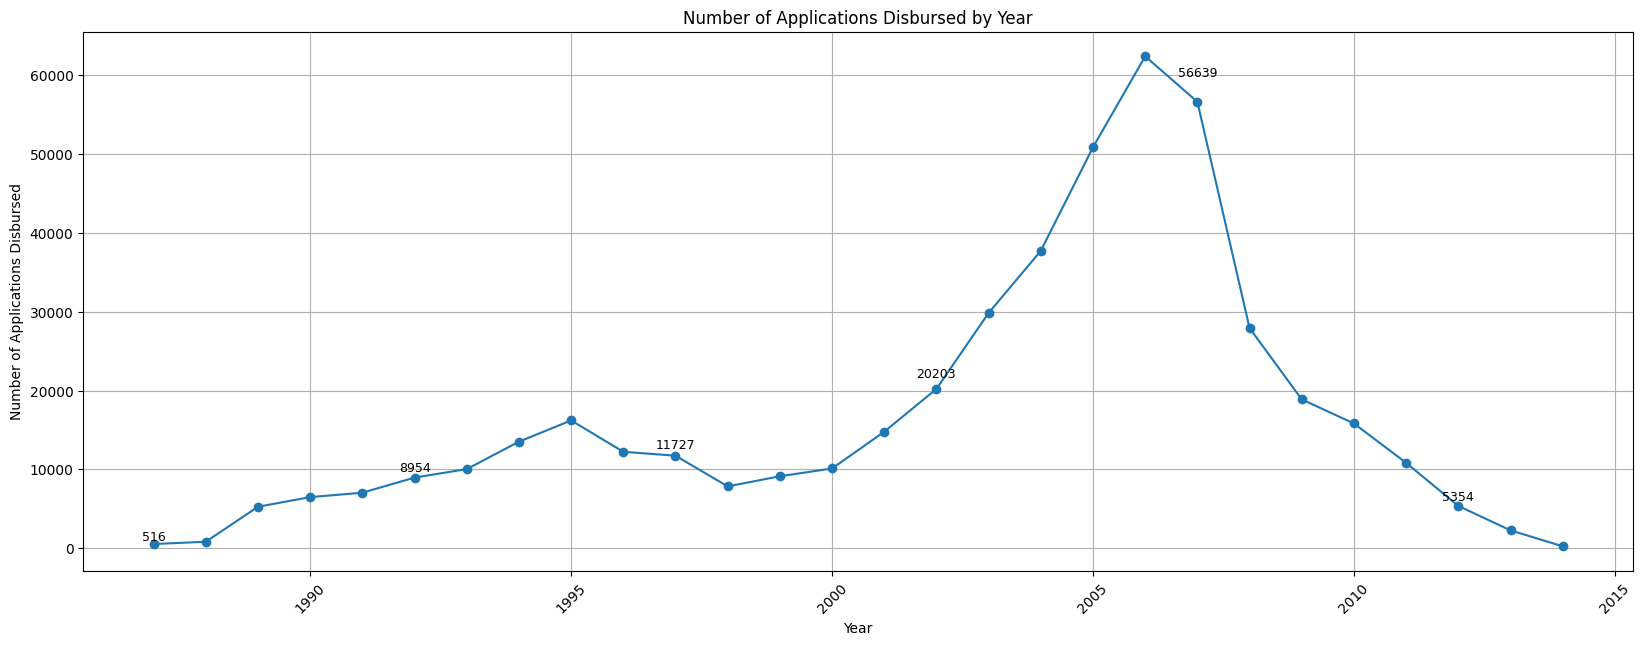

In [ ]:
# Time Series Graph for DisbursementYear
SBA_df3 = SBA_df2[['DisbursementYear']]

# Convert ApprovalFY to numeric, forcing errors to NaN and then drop NaNs
SBA_df3['DisbursementYear'] = pd.to_numeric(SBA_df3['DisbursementYear'], errors='coerce')

# Count the number of applications approved each year
approval_count = SBA_df3['DisbursementYear'].value_counts().sort_index()

# Plot
plt.figure(figsize=(20, 7))
plt.plot(approval_count.index, approval_count.values, marker='o')
plt.xlabel('Year')
plt.ylabel('Number of Applications Disbursed')
plt.title('Number of Applications Disbursed by Year')
plt.grid(True)
plt.xticks(rotation=45)

# Add selective data labels with an offset above the points
for i, (x, y) in enumerate(zip(approval_count.index, approval_count.values)):
    if i % 5 == 0:  # Show label every 5th year
        plt.text(x, y + y * 0.05, str(y), ha='center', va='bottom', fontsize=9)  # Offset by 5%

plt.show()

<ipython-input-174-7126847359fc>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  SBA_df3['ApprovalFY'] = SBA_df2['ApprovalFY'].astype(int)
<ipython-input-174-7126847359fc>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  SBA_df3['DisbursementYear'] = SBA_df2['DisbursementYear'].astype(int)


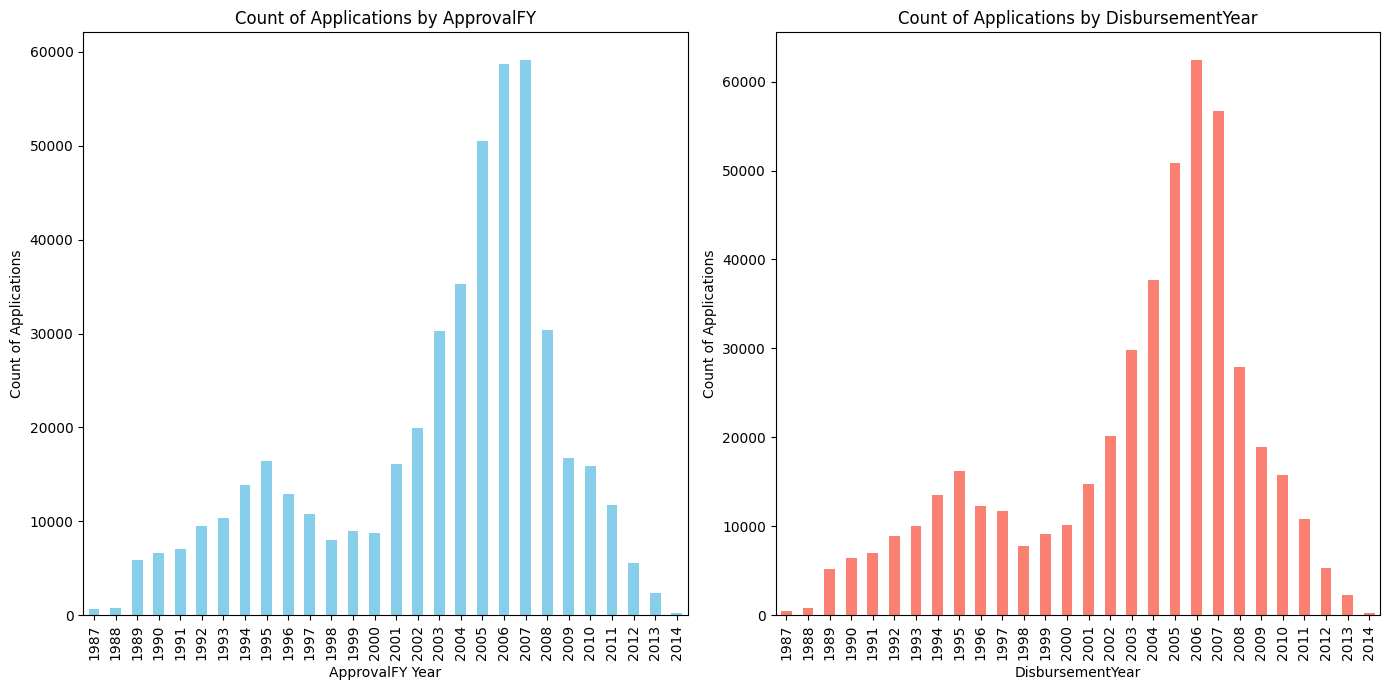

In [ ]:
# Make ApprovalFY and DisbursmentYear int first
SBA_df3['ApprovalFY'] = SBA_df2['ApprovalFY'].astype(int)
SBA_df3['DisbursementYear'] = SBA_df2['DisbursementYear'].astype(int)

# Create a new DataFrame with the desired columns

# Count occurrences for each year in ApprovalFY
approval_counts = SBA_df3['ApprovalFY'].value_counts().sort_index()

# Count occurrences for each year in DisbursementYear
disbursement_counts = SBA_df3['DisbursementYear'].value_counts().sort_index()

# Plot the counts for both columns side by side
plt.figure(figsize=(14, 7))

# Plot ApprovalFY counts
plt.subplot(1, 2, 1)
approval_counts.plot(kind='bar', color='skyblue')
plt.title('Count of Applications by ApprovalFY')
plt.xlabel('ApprovalFY Year')
plt.ylabel('Count of Applications')

# Plot DisbursementYear counts
plt.subplot(1, 2, 2)
disbursement_counts.plot(kind='bar', color='salmon')
plt.title('Count of Applications by DisbursementYear')
plt.xlabel('DisbursementYear')
plt.ylabel('Count of Applications')

plt.tight_layout()
plt.show()

Count of Approval Year and Disbursement Year above visualize simialr patterns. Dropping Approval Year to remove possible similar values.

In [ ]:
# Drop ApprovalFY
SBA_df2 = SBA_df2.drop(['ApprovalFY'], axis=1)

# **Examining Numeric Variables**

In [ ]:
# Looking at dataframe to determine numerical variables
SBA_df2.dtypes

,0
NoEmp,int64
NewExist,float64
FranchiseCode,int64
UrbanRural,int64
RevLineCr,object
LowDoc,object
DisbursementGross,float64
MIS_Status,int64
GrAppv,float64
SBA_Appv,float64


In [ ]:
# Suppress scientific notation for display
pd.set_option('display.float_format', '{:.2f}'.format)

# Optionally, adjust display settings to prevent wrapping to a new line
pd.set_option('display.width', 1000)  # Increase the display width
pd.set_option('display.max_columns', None)  # Ensure all columns are displayed

# Describe numerical variables
numerical_descriptions = SBA_df2[['NoEmp', 'DisbursementGross', 'GrAppv', 'SBA_Appv']].describe()
numerical_descriptions

,NoEmp,DisbursementGross,GrAppv,SBA_Appv
count,473529.00,473529.00,473529.00,473529.00
mean,9.79,169384.85,150914.86,114351.46
std,55.94,273356.87,258637.33,212023.77
min,0.00,0.00,200.00,100.00
25%,2.00,33730.00,25000.00,12500.00
50%,4.00,75000.00,50000.00,32500.00
75%,9.00,186910.00,150000.00,120000.00
max,9999.00,11446325.00,5000000.00,4500000.00


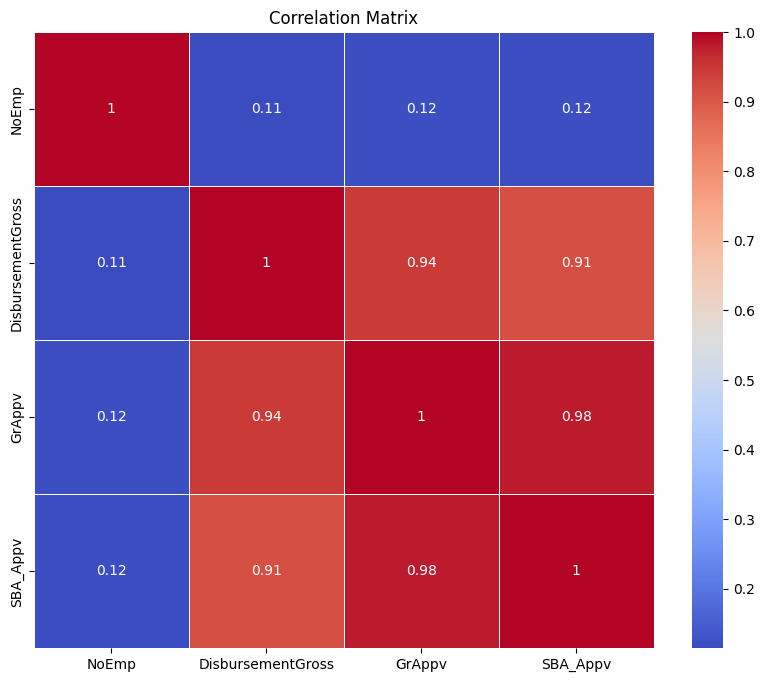

In [ ]:
# Dataframe for numerical variables
SBA_df3 = SBA_df2[['NoEmp', 'DisbursementGross', 'GrAppv', 'SBA_Appv']]

# Correlation Matrix
correlation_matrix = SBA_df3.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

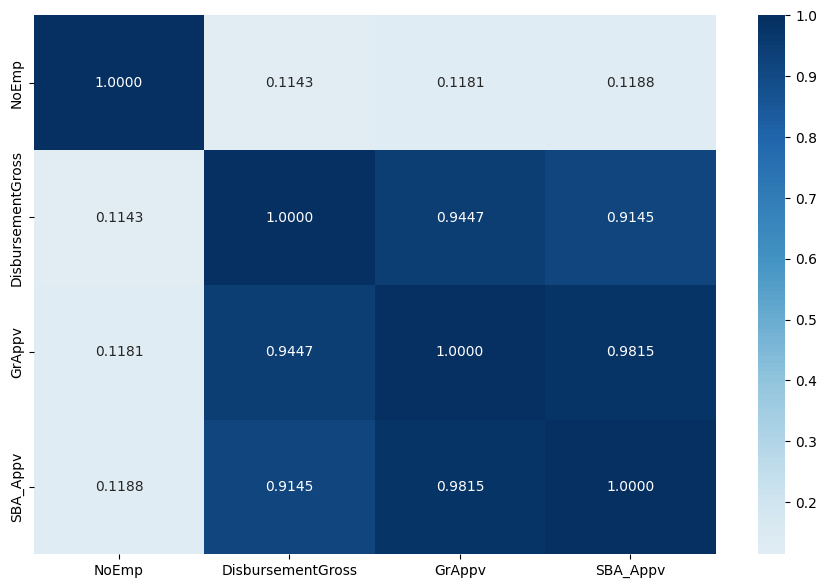

In [ ]:
# Dataframe for numerical variables
SBA_df3 = SBA_df2[['NoEmp', 'DisbursementGross', 'GrAppv', 'SBA_Appv']]

# Correlation Matrix
corr = SBA_df3.corr()
fig, ax = plt.subplots()
fig.set_size_inches(11, 7)
sns.heatmap(corr, annot=True, fmt=".4f", cmap="RdBu", center=0, ax=ax)
plt.show()

In [ ]:
# Dataframe for numerical variables
SBA_df3 = SBA_df2[['NoEmp', 'DisbursementGross', 'GrAppv', 'SBA_Appv']]

# Correlation Matrix
corr = SBA_df3.corr()

# Unstack and filter the correlations
strong_corr = corr.unstack().reset_index()
strong_corr.columns = ['Variable 1', 'Variable 2', 'Correlation']

# Remove self-correlations
strong_corr = strong_corr[strong_corr['Variable 1'] != strong_corr['Variable 2']]

# Ensure unique pairs by sorting the variable names
strong_corr['Pair'] = strong_corr.apply(lambda x: tuple(sorted((x['Variable 1'], x['Variable 2']))), axis=1)
strong_corr = strong_corr.drop_duplicates(subset='Pair').drop(columns='Pair')

# Sort the correlations by absolute values
strong_corr = strong_corr.sort_values(by='Correlation', key=abs, ascending=False)

# Select the top n strongest correlations (for example, top 10)
top_n = 10
strongest_correlations = strong_corr.head(top_n)

# Display the DataFrame of strongest correlations
strongest_correlations

,Variable 1,Variable 2,Correlation
11,GrAppv,SBA_Appv,0.98
6,DisbursementGross,GrAppv,0.94
7,DisbursementGross,SBA_Appv,0.91
3,NoEmp,SBA_Appv,0.12
2,NoEmp,GrAppv,0.12
1,NoEmp,DisbursementGross,0.11


Based on output above, choosing to drop GrAppv due to its high correlation to SBA_Appv.

In [ ]:
# Drop GrApprov
SBA_df2 = SBA_df2.drop(['GrAppv'], axis=1)

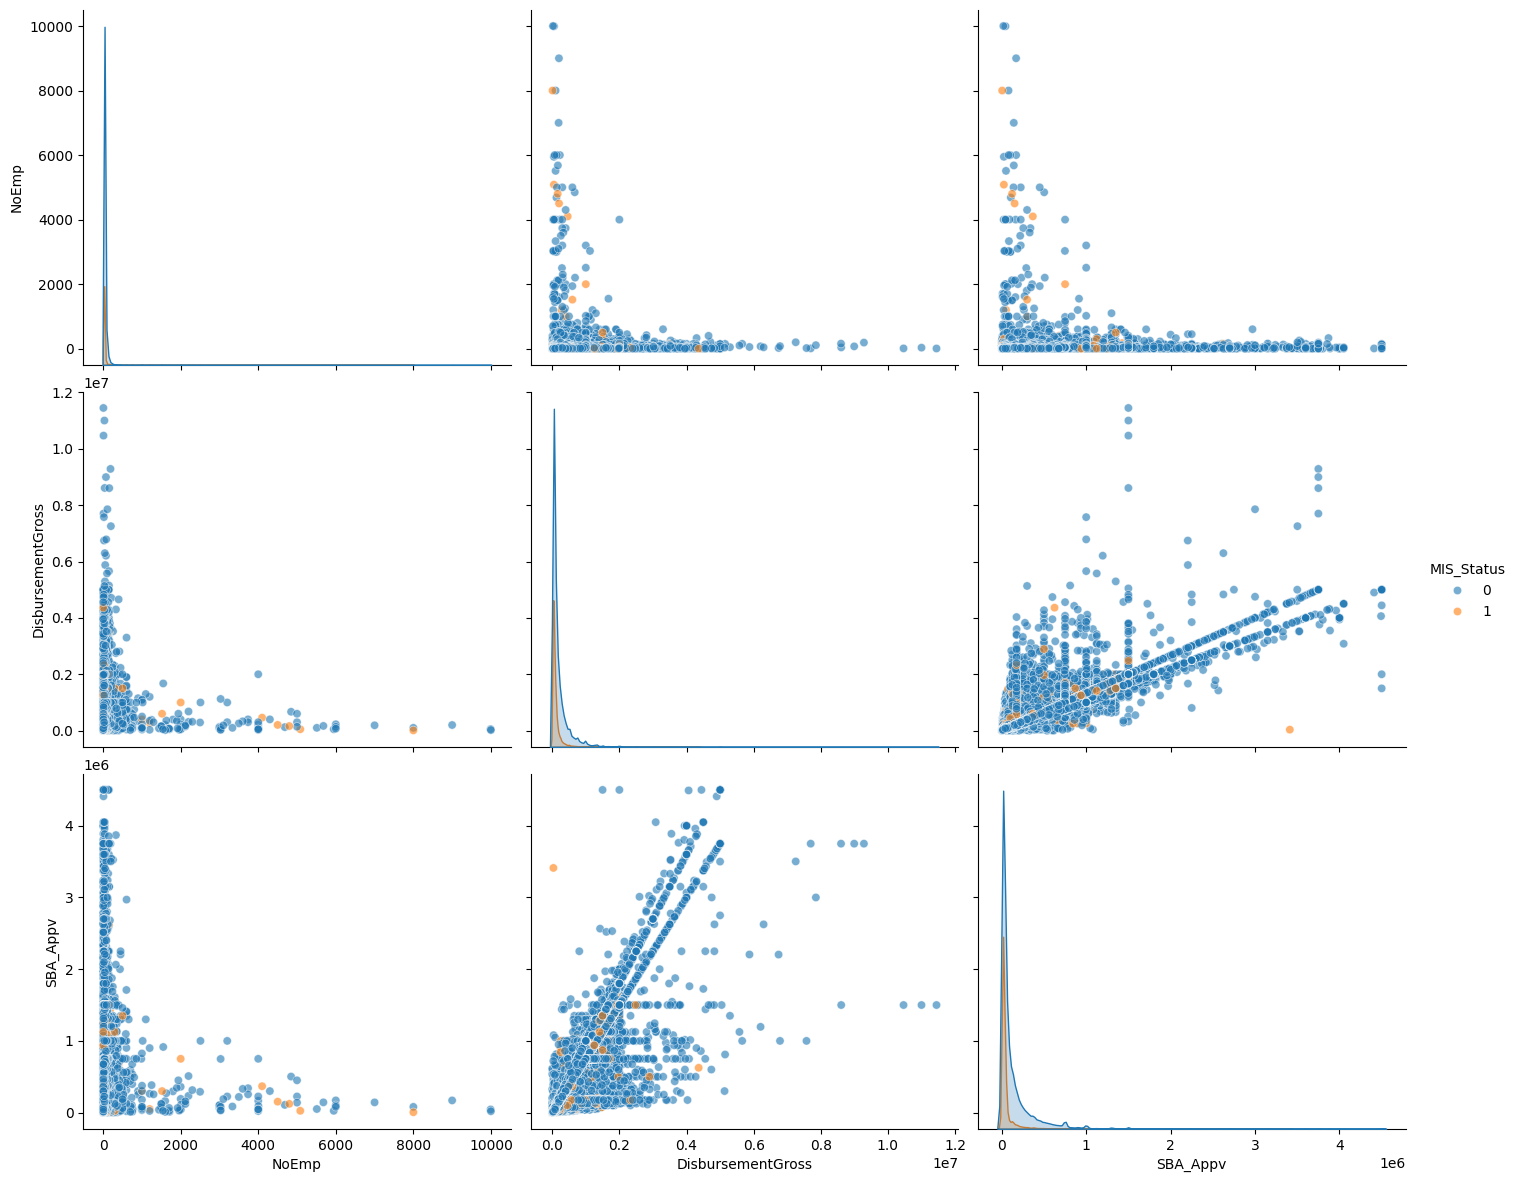

In [ ]:
# Pairwise plots
# Create df with numeric and y
SBA_df3 = SBA_df2[['NoEmp', 'DisbursementGross', 'SBA_Appv', 'MIS_Status']]

# Plotting
sns.pairplot(SBA_df3, hue='MIS_Status', height=4, aspect=1.2, plot_kws={'alpha':0.6})
plt.show()

# Dropping DistributionYear for Recession Variable

Add variable for Recession years. Used to exammine if recession years have an influence of loan default or loan paid of rate. Remove DistributionYear as we no longer need this.

In [ ]:
# Group DisbursementYear by Recession years and non Recession year

# List of recession years (from previous response)
recession_years = [ 1990, 1991, 2001, 2007, 2008, 2009]

# Create a new column 'Recession' where 1 indicates a recession year, 0 otherwise
SBA_df2['Recession'] = SBA_df2['DisbursementYear'].apply(lambda x: 1 if x in recession_years else 0)

# Drop the 'DisbursementYear' column
SBA_df2 = SBA_df2.drop(columns=['DisbursementYear'])

# Verify
print(SBA_df2['Recession'].value_counts())

Recession
0    341824
1    131705
Name: count, dtype: int64


# **Save to new CSV for Easier Access**

In [ ]:
# Save to drive
SBA_df2.to_csv('/content/drive/My Drive/MSBA/MSBA BA Project/SBA_clean.csv', index=False)